# Paper title
## What this repo reproduces

| Paper element | Notebook section | Output file |
|---|---|---|
| Table 2 (empirical metrics) | §3 | — |
| Fig. 3 (Q-Q inter-arrival) | §17 | QQ_Plots_Validation.png (left) |
| Fig. 4 (Q-Q service) | §17 | QQ_Plots_Validation.png (right) |
| Fig. 5 (μ₀ and LONO RMSE) | §15 | Models_comparison.png |
| Fig. 6 (q profile) | §20 | q_profile.png |
| Fig. 7 (q sensitivity heatmap) | §21 | q_sensitivity.png |
| Table 4 (best q per R) | §22 | — |

In [1]:
# =============================================================
# 1. Imports and constants
# =============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

A_GLOBAL = 8.0            # total cores on the node
Q_GLOBAL = 8.0 / 240.0    # CPU quota per container
LAM      = 90.0          # arrival rate, req/s

# =============================================================
# 2. Data loading and preprocessing
# =============================================================
COLS = [
    "request_id", "arrival_time_iso", "arrival_time_ms",
    "inter_arrival_time", "requested_service_time", "bottleneck_type",
    "iteration", "servers", "capacity", "mu", "lambda",
    "num_requests", "response_time_ms", "actual_service_time",
    "waiting_time_ms", "success", "blocked", "error",
]

FILES = [
    "20260309_19_51_data.csv",
    "20260318_10_47_data.csv",
    "20260318_16_07_data.csv",
]

# Tag each file so we can later diff arrival clocks per-experiment,
# not across files (each file's arrival_time_ms restarts at 0).
frames = []
for f in FILES:
    df = pd.read_csv(f, header=None, names=COLS)
    df["source_file"] = f
    frames.append(df)
raw = pd.concat(frames, ignore_index=True)

# Drop network-level errors (model doesn't describe them)
raw = raw[~((~raw["success"]) & (~raw["blocked"]))].copy()

# Unit conversions
raw["response_time_s"] = raw["response_time_ms"] / 1000.0
raw["waiting_time_s"]  = raw["waiting_time_ms"]  / 1000.0
# actual_service_time is already in seconds

# Derived keys
raw["m"]     = raw["capacity"] - raw["servers"]
raw["R_cpu"] = raw["iteration"] * 0.5

# Drop the infinite-queue runs (model assumes finite m)
raw = raw[raw["capacity"] != 500].copy()

# NOTE: include source_file, otherwise the same (iteration, servers,
# capacity) triple from different files collapses into one ID.
raw['experiment_id'] = raw.groupby(
    ['source_file', 'iteration', 'servers', 'capacity']
).ngroup()

print(f"Rows after cleaning: {len(raw)}")
print(f"R_cpu: {sorted(raw['R_cpu'].unique())}")
print(f"n    : {sorted(raw['servers'].unique())}")
print(f"m    : {sorted(raw['m'].unique())}")


# =============================================================
# 3. Empirical metrics per (n, m, R_cpu)
# =============================================================
def empirical_metrics(g, R, n, m, lam_actual):
    N = len(g)
    P_loss = float(g["blocked"].mean())

    succ = g[g["success"]]
    if len(succ) == 0:
        return {
            "n": n, "m": m, "R_cpu": R, "N": N, "N_succ": 0,
            "lam_actual": lam_actual,
            "P_loss": P_loss,
            "T": np.nan, "T_q": np.nan, "T_serv": np.nan,
            "L": np.nan, "L_q": np.nan, "L_serv": np.nan,
            "mu_emp": np.nan,
        }

    T_serv = float(succ["actual_service_time"].mean())
    T_q    = float(succ["waiting_time_s"].mean())
    T      = float(succ["response_time_s"].mean())

    lam_eff = lam_actual * (1.0 - P_loss)
    L       = lam_eff * T
    L_q     = lam_eff * T_q

    return {
        "n": n, "m": m, "R_cpu": R, "N": N, "N_succ": len(succ),
        "lam_actual": lam_actual,
        "P_loss": P_loss,
        "T": T, "T_q": T_q, "T_serv": T_serv,
        "L": L, "L_q": L_q, "L_serv": L - L_q,   # NEW
        "mu_emp": 1.0 / T_serv if T_serv > 0 else np.nan,
    }

# Precompute per-cell actual lambda
def measured_lambda(g):
    g = g.sort_values("arrival_time_ms")
    dur_s = (g["arrival_time_ms"].iloc[-1] - g["arrival_time_ms"].iloc[0]) / 1000.0
    return (len(g) - 1) / dur_s if dur_s > 0 else np.nan

lam_per_cell = (raw.groupby(["R_cpu", "servers", "m"])
                   .apply(measured_lambda, include_groups=False)
                   .rename("lam_actual")
                   .reset_index())

emp_rows = []
for (R, n, m), g in raw.groupby(["R_cpu", "servers", "m"], sort=True):
    lam_cell = float(lam_per_cell.loc[
        (lam_per_cell["R_cpu"] == R) &
        (lam_per_cell["servers"] == n) &
        (lam_per_cell["m"] == m), "lam_actual"].iloc[0])
    emp_rows.append(empirical_metrics(g, float(R), int(n), int(m), lam_cell))

emp = pd.DataFrame(emp_rows)

Rows after cleaning: 1127990
R_cpu: [np.float64(0.0), np.float64(0.5), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0), np.float64(3.5), np.float64(4.0), np.float64(4.5), np.float64(5.0), np.float64(5.5), np.float64(6.0), np.float64(6.5), np.float64(7.0)]
n    : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(10), np.int64(12), np.int64(18), np.int64(20), np.int64(28), np.int64(35), np.int64(45), np.int64(50), np.int64(70), np.int64(95), np.int64(100), np.int64(125), np.int64(150), np.int64(155), np.int64(185), np.int64(200), np.int64(215), np.int64(235), np.int64(240)]
m    : [np.int64(0), np.int64(10), np.int64(20), np.int64(40), np.int64(50), np.int64(60), np.int64(80), np.int64(100)]


In [2]:

# =============================================================
# 4. Theoretical model (finite-buffer M/M-type, state-dependent mu)
# =============================================================
def model_metrics(mu0, n, m, R_cpu, lam=LAM, A=A_GLOBAL, Q=Q_GLOBAL):
    """
    Returns dict with model-predicted metrics for a single (n,m,R_cpu).
    Stable log-space recursion; handles a = lam/mu0 up to ~1e3.
    """
    if mu0 <= 0:
        raise ValueError("mu0 must be positive")

    s = min(n, int(np.floor((A - R_cpu) / Q)))    # active containers at full quota
    K = n + m                                     # total capacity (states 0..K)

    a   = lam / mu0
    rho = lam / (s * mu0)

    # log pi_k (unnormalized), pi_0 = 1
    log_pi = np.zeros(K + 1)
    for k in range(1, s + 1):
        log_pi[k] = log_pi[k-1] + np.log(a) - np.log(k)
    for k in range(s + 1, K + 1):
        log_pi[k] = log_pi[k-1] + np.log(rho)

    log_pi -= log_pi.max()          # shift for numerical stability
    p = np.exp(log_pi)
    p /= p.sum()

    P_loss = float(p[K])
    L      = float(np.dot(np.arange(K + 1), p))
    k_axis = np.arange(K + 1)
    L_serv = float(np.dot(np.minimum(k_axis, s), p))
    L_q    = L - L_serv

    lam_eff = lam * (1.0 - P_loss)
    if lam_eff <= 0:
        T = T_q = T_serv = np.inf
    else:
        T      = L      / lam_eff
        T_q    = L_q    / lam_eff
        T_serv = L_serv / lam_eff

    return {
        "s": s, "P_loss": P_loss,
        "L": L, "L_q": L_q, "L_serv": L_serv,
        "T": T, "T_q": T_q, "T_serv": T_serv,
        "lam_eff": lam_eff, "p": p,
    }


# =============================================================
# 5. Sanity tests
# =============================================================
def run_sanity_tests():
    # -- Test 1: M/M/1/1 (Erlang loss) -----------------------------------
    # n=1, m=0, s=1, lam=100, mu0=2  ->  P_loss = a/(1+a), a = lam/mu0
    r = model_metrics(mu0=2.0, n=1, m=0, R_cpu=7.0)
    a = LAM / 2.0
    assert abs(r["P_loss"] - a / (1.0 + a)) < 1e-12, r["P_loss"]
    print("T1  Erlang loss (M/M/1/1)                    OK")

    # -- Test 2: P_loss -> 0 as m -> inf when rho < 1 --------------------
    # Need mu0 > lam/s = 100/5 = 20 so that rho < 1.
    r_small = model_metrics(mu0=30.0, n=5, m=10,  R_cpu=7.0)
    r_large = model_metrics(mu0=30.0, n=5, m=200, R_cpu=7.0)
    assert r_small["s"] == 5
    # rho = 100/(5*30) = 0.667
    assert r_large["P_loss"] < r_small["P_loss"] < 1.0
    assert r_large["P_loss"] < 1e-9
    print("T2  P_loss -> 0 for m -> inf (rho < 1)      OK")

    # -- Test 2b: P_loss -> 1 - 1/rho for rho > 1, K -> inf --------------
    # Expected limit is 1 - 1/rho where rho = LAM / (s * mu0).
    # Use LAM (not a hard-coded 100) so the test tracks the notebook constant.
    r_small_over = model_metrics(mu0=2.0, n=5, m=10,  R_cpu=7.0)
    r_large_over = model_metrics(mu0=2.0, n=5, m=500, R_cpu=7.0)
    s_over   = r_large_over["s"]
    rho_over = LAM / (s_over * 2.0)
    limit    = 1.0 - 1.0 / rho_over
    assert rho_over > 1.0
    assert abs(r_large_over["P_loss"] - limit) < 1e-9, (r_large_over["P_loss"], limit)
    assert abs(r_small_over["P_loss"] - limit) < 1e-2, (r_small_over["P_loss"], limit)
    print(f"T2b P_loss -> 1 - 1/rho = {limit:.4f}           OK")

    # -- Test 3: P_loss -> 0 for lam -> 0 --------------------------------
    r = model_metrics(mu0=1.0, n=10, m=5, R_cpu=7.0, lam=1e-4)
    assert r["P_loss"] < 1e-12
    print("T3  P_loss -> 0 for lam -> 0                OK")

    # -- Test 4: P_loss monotone decreasing in mu0 -----------------------
    mus = np.linspace(0.5, 5.0, 30)
    pls = [model_metrics(mu0, n=20, m=30, R_cpu=4.0)["P_loss"] for mu0 in mus]
    assert all(pls[i] > pls[i+1] for i in range(len(pls)-1))
    print("T4  P_loss monotone in mu0                  OK")

    # -- Test 5: Little's law in the model -------------------------------
    r = model_metrics(mu0=2.0, n=10, m=20, R_cpu=4.0)
    assert abs(r["L"]   - r["lam_eff"] * r["T"])   < 1e-10
    assert abs(r["L_q"] - r["lam_eff"] * r["T_q"]) < 1e-10
    print("T5  Little's law (L and L_q)                OK")

    # -- Test 6: s = n when quota ratio exceeds n ------------------------
    # R_cpu = 0 -> (A-R)/q = 240; n=100 -> s=100
    r = model_metrics(mu0=1.0, n=100, m=10, R_cpu=0.0)
    assert r["s"] == 100
    # R_cpu = 7 -> (A-R)/q = 30; n=100 -> s=30
    r = model_metrics(mu0=1.0, n=100, m=10, R_cpu=7.0)
    assert r["s"] == 30
    print("T6  s = min(n, (A-R)/q)                     OK")

    # -- Test 7: normalization -------------------------------------------
    r = model_metrics(mu0=1.0, n=50, m=50, R_cpu=3.0)
    assert abs(r["p"].sum() - 1.0) < 1e-12
    print("T7  State probabilities sum to 1            OK")

    # -- Test 8: number in service bounded by n --------------------------
    r = model_metrics(mu0=1.0, n=50, m=50, R_cpu=3.0)
    assert 0 <= r["L_serv"] <= 50 + 1e-9
    print("T8  0 <= L_serv <= n                        OK")

run_sanity_tests()

T1  Erlang loss (M/M/1/1)                    OK
T2  P_loss -> 0 for m -> inf (rho < 1)      OK
T2b P_loss -> 1 - 1/rho = 0.8889           OK
T3  P_loss -> 0 for lam -> 0                OK
T4  P_loss monotone in mu0                  OK
T5  Little's law (L and L_q)                OK
T6  s = min(n, (A-R)/q)                     OK
T7  State probabilities sum to 1            OK
T8  0 <= L_serv <= n                        OK


In [3]:
# -------------------------------------------------------------
# Additions for downstream cells
# -------------------------------------------------------------
succ = raw[raw["success"]].copy()
print(f"Successful requests: {len(succ)}")
print(f"  mean T_serv = {succ['actual_service_time'].mean():.4f} s")
print(f"  1/mean     = {1.0/succ['actual_service_time'].mean():.4f} req/s")

Successful requests: 613146
  mean T_serv = 0.9650 s
  1/mean     = 1.0363 req/s


In [4]:
# =============================================================
# Extended model: per-container concurrency multiplier p
# =============================================================
def model_metrics_v2(mu0, n, m, R_cpu, lam=LAM,
                     A=A_GLOBAL, q=Q_GLOBAL, p=1.0):
    """
    Finite-buffer M/M-type model with a concurrency multiplier p.

    p = 1  -> original model:  s = min(n, (A-R)/q),  K = n + m
    p > 1  -> each container runs up to p concurrent request slots, each
              at rate mu0. Effective slot count scales with p; total
              throughput is s * mu0 where s grows linearly with p. The
              model is phenomenological and does not resolve how the p
              slots share the container's CPU quota q.

    Both the service-slot cap s and the total capacity K use floor(p*n):
    a container can hold at most floor(p*n) requests in service, and the
    remaining K - s = m states are exactly the m buffer places.  (Using
    ceil for K while flooring s would create one unreachable state whose
    service occupancy exceeds the container cap.)

    Returns the same keys as the original model_metrics() plus:
        'p'  : the concurrency multiplier used
        'K'  : total system capacity (container slots + buffer)
    """
    if mu0 <= 0 or p <= 0:
        raise ValueError("mu0 and p must be positive")

    # ---- Total capacity: floor(p*n) container slots, plus m buffer ----
    K = int(np.floor(n * p)) + m

    # ---- Number of processing slots ----
    s_cpu  = p * (A - R_cpu) / q
    s_cont = p * n
    s = int(np.floor(min(s_cpu, s_cont)))

    # Per-slot rate: mu0 is the per-slot rate (paper's definition)
    a   = lam / mu0
    rho = lam / (s * mu0)

    # ---- Stable log-space recursion for the stationary distribution ----
    log_pi = np.zeros(K + 1)
    for k in range(1, s + 1):
        log_pi[k] = log_pi[k - 1] + np.log(a) - np.log(k)
    for k in range(s + 1, K + 1):
        log_pi[k] = log_pi[k - 1] + np.log(rho)

    log_pi -= log_pi.max()
    pi = np.exp(log_pi)
    pi /= pi.sum()

    P_loss = float(pi[K])
    L      = float(np.dot(np.arange(K + 1), pi))

    # Slots in use = min(k, s)
    k_axis = np.arange(K + 1)
    L_serv = float(np.dot(np.minimum(k_axis, s), pi))
    L_q    = L - L_serv

    lam_eff = lam * (1.0 - P_loss)
    if lam_eff <= 0:
        T = T_q = T_serv = np.inf
    else:
        T      = L      / lam_eff
        T_q    = L_q    / lam_eff
        T_serv = L_serv / lam_eff

    return {
        "s": s, "p": p, "K": K, "P_loss": P_loss,
        "L": L, "L_q": L_q, "L_serv": L_serv,
        "T": T, "T_q": T_q, "T_serv": T_serv,
        "lam_eff": lam_eff, "pi": pi,
    }

In [5]:
r_old = model_metrics(2.0, n=20, m=30, R_cpu=4.0)
r_new = model_metrics_v2(2.0, n=20, m=30, R_cpu=4.0, p=1.0)

# should be identical
assert r_old["P_loss"] == r_new["P_loss"]
assert r_old["L"] == r_new["L"]

In [6]:
from scipy.optimize import differential_evolution

MAX_CELL_LOSS = 1e6   # module-level constant, reused by _sse later

def calibrate_baseline_joint(emp_sub, w_T=1.0, w_L=0.0):
    """
    Fix p = 1 and fit mu0 on the same joint loss as the extended model.

    Each cell contributes a bounded amount; a bad cell (non-finite
    T_serv, non-finite P_loss, etc.) contributes MAX_CELL_LOSS, and an
    extreme-but-finite cell is clipped at MAX_CELL_LOSS.  Without the
    cap, the 1e12 sentinel is *smaller* than ((1e20-0.95)/0.95)^2, so
    DE would prefer to drive T_serv non-finite rather than minimize
    the real loss.

    Uses the same DE seed/budget as calibrate_v2_joint so that the
    baseline and extended fits differ only in the number of free
    parameters.
    """
    cols = ["P_loss", "T_serv"] + (["L_serv"] if w_L > 0 else [])
    sub  = emp_sub.dropna(subset=cols).copy()
    if len(sub) == 0:
        return np.nan, np.nan, 0, np.nan

    R       = float(sub["R_cpu"].iloc[0])
    lam_use = float(sub["lam_actual"].mean())

    ns  = sub["n"].astype(int).values
    ms  = sub["m"].astype(int).values
    pls = sub["P_loss"].values
    tss = sub["T_serv"].values
    lss = sub["L_serv"].values if w_L > 0 else None

    def sse(theta):
        mu0 = np.exp(theta[0])
        tot = 0.0
        for i in range(len(ns)):
            try:
                r = model_metrics_v2(mu0, ns[i], ms[i], R_cpu=R,
                                     lam=lam_use, p=1.0)
            except Exception:
                tot += MAX_CELL_LOSS
                continue
            if not np.isfinite(r["P_loss"]):
                tot += MAX_CELL_LOSS
                continue
            cell = (r["P_loss"] - pls[i]) ** 2
            ts = tss[i]
            if ts > 0 and np.isfinite(r["T_serv"]):
                cell += w_T * ((r["T_serv"] - ts) / ts) ** 2
            else:
                cell += MAX_CELL_LOSS
            if w_L > 0:
                ls = lss[i]
                if ls > 0 and np.isfinite(r["L_serv"]):
                    cell += w_L * ((r["L_serv"] - ls) / ls) ** 2
                else:
                    cell += MAX_CELL_LOSS
            tot += min(cell, MAX_CELL_LOSS)
        return tot   # <-- outside the for loop

    res = differential_evolution(
        sse,
        bounds=[(np.log(0.05), np.log(50.0))],
        seed=0, maxiter=300, tol=1e-9, polish=True)

    if res.fun >= len(ns) * MAX_CELL_LOSS * 0.9:
        raise RuntimeError(
            f"DE failed at R_cpu={R}: fun={res.fun:.3e}, "
            f"mu0={np.exp(res.x[0]):.4f}.  Nearly every cell is at the "
            f"cap; check emp rows and model_metrics_v2 for this R.")

    return float(np.exp(res.x[0])), float(res.fun), len(sub), lam_use

In [7]:
# =============================================================
# Joint calibration of (mu0, p) on P_loss and T_serv
# =============================================================
from scipy.optimize import differential_evolution

def calibrate_v2_joint(emp_sub, w_T=1.0, w_L=0.0):
    """
    Fit (mu0, p) for one R_cpu group.

    Objective:
        sum_k [ (P_loss_mod - P_loss_emp)^2
              + w_T * ((T_serv_mod - T_serv_emp) / T_serv_emp)^2
              + w_L * ((L_serv_mod - L_serv_emp) / L_serv_emp)^2 ]

    P_loss is on an absolute scale (already in [0, 1]).
    T_serv and L_serv are on a relative scale.

    differential_evolution is used because s depends on p through a floor(),
    which makes the SSE piecewise constant in p — L-BFGS-B's numerical
    gradient cannot navigate that.

    Returns: (mu0_hat, p_hat, SSE, n_obs, lam_used)
    """
    cols = ["P_loss", "T_serv"] + (["L_serv"] if w_L > 0 else [])
    sub  = emp_sub.dropna(subset=cols).copy()
    if len(sub) == 0:
        return np.nan, np.nan, np.nan, 0, np.nan

    R       = float(sub["R_cpu"].iloc[0])
    lam_use = float(sub["lam_actual"].mean())

    ns  = sub["n"].astype(int).values
    ms  = sub["m"].astype(int).values
    pls = sub["P_loss"].values
    tss = sub["T_serv"].values
    lss = sub["L_serv"].values if w_L > 0 else None

    def sse(theta):
        mu0 = np.exp(theta[0])
        p   = np.exp(theta[1])
        tot = 0.0
        for i in range(len(ns)):
            try:
                r = model_metrics_v2(mu0, ns[i], ms[i], R_cpu=R,
                                     lam=lam_use, p=p)
            except Exception:
                return 1e12

            if not np.isfinite(r["P_loss"]):
                return 1e12
            tot += (r["P_loss"] - pls[i]) ** 2

            ts = tss[i]
            if ts > 0 and np.isfinite(r["T_serv"]):
                tot += w_T * ((r["T_serv"] - ts) / ts) ** 2
            else:
                return 1e12

            if w_L > 0:
                ls = lss[i]
                if ls > 0 and np.isfinite(r["L_serv"]):
                    tot += w_L * ((r["L_serv"] - ls) / ls) ** 2
                else:
                    return 1e12

        return tot

    res = differential_evolution(
        sse,
        bounds=[(np.log(0.05), np.log(50.0)),    # mu0
                (np.log(1.00), np.log(20.0))],   # p >= 1
        seed=0,
        maxiter=300,
        tol=1e-9,
        polish=True,
    )

    mu0 = float(np.exp(res.x[0]))
    p   = float(np.exp(res.x[1]))
    return mu0, p, float(res.fun), len(sub), lam_use

In [8]:
calib_rows = []
for R, sub in emp.groupby("R_cpu"):
    mu0_hat, sse, n_obs, lam_use = calibrate_baseline_joint(sub)
    calib_rows.append({"R_cpu": R, "mu0_hat": mu0_hat,
                       "lam_used": lam_use,
                       "SSE": sse, "n_obs": n_obs,
                       "RMSE": np.sqrt(sse / n_obs)})
calib = pd.DataFrame(calib_rows)
print("\nCalibration results per R_cpu (baseline, joint loss):")
print(calib.to_string(index=False))


Calibration results per R_cpu (baseline, joint loss):
 R_cpu  mu0_hat  lam_used      SSE  n_obs     RMSE
   0.0 1.047660 89.324299 2.378743    192 0.111307
   0.5 1.047103 89.535800 3.106223    192 0.127194
   1.0 1.050671 89.387198 2.995543    192 0.124907
   1.5 1.052721 89.890539 2.555458    192 0.115368
   2.0 1.047498 89.878313 2.503912    192 0.114198
   2.5 1.048845 89.708344 2.669920    192 0.117923
   3.0 1.049346 89.529079 3.065263    192 0.126352
   3.5 1.049905 89.523660 2.686353    192 0.118285
   4.0 1.049726 89.498673 3.019282    192 0.125401
   4.5 1.049428 89.480938 2.924577    192 0.123419
   5.0 1.053074 89.218859 1.961813     96 0.142953
   5.5 1.065623 89.276056 1.827452     96 0.137971
   6.0 1.107299 88.945982 1.842282     48 0.195910
   6.5 1.125962 89.036164 3.029141     48 0.251211
   7.0 1.147359 89.031241 5.887182     48 0.350214


In [9]:
import pandas as pd

# ---------- Run the joint calibration for every R_cpu ----------
calib2_rows = []
for R, sub in emp.groupby("R_cpu"):
    mu0, p, sse, n_obs, lam_used = calibrate_v2_joint(sub, w_T=1.0, w_L=0.0)
    calib2_rows.append({
        "R_cpu":    R,
        "mu0_hat":  mu0,
        "p_hat":    p,
        "lam_used": lam_used,
        "SSE":      sse,
        "n_obs":    n_obs,
        "RMSE":     np.sqrt(sse / n_obs) if n_obs else np.nan,
    })
calib2 = pd.DataFrame(calib2_rows)
print(calib2.round(3).to_string(index=False))

 R_cpu  mu0_hat  p_hat  lam_used   SSE  n_obs  RMSE
   0.0    1.048  1.005    89.324 2.379    192 0.111
   0.5    1.047  1.006    89.536 3.106    192 0.127
   1.0    1.051  1.004    89.387 2.996    192 0.125
   1.5    1.053  1.006    89.891 2.555    192 0.115
   2.0    1.047  1.004    89.878 2.504    192 0.114
   2.5    1.049  1.002    89.708 2.670    192 0.118
   3.0    1.049  1.005    89.529 3.065    192 0.126
   3.5    1.050  1.001    89.524 2.686    192 0.118
   4.0    1.050  1.002    89.499 3.019    192 0.125
   4.5    1.049  1.001    89.481 2.925    192 0.123
   5.0    1.053  1.002    89.219 1.962     96 0.143
   5.5    1.063  1.017    89.276 1.819     96 0.138
   6.0    1.057  1.251    88.946 1.414     48 0.172
   6.5    1.046  1.579    89.036 1.384     48 0.170
   7.0    1.056  2.238    89.031 1.705     48 0.188


In [10]:
from scipy.optimize import curve_fit

sub = calib2[calib2["R_cpu"] >= 5.5]

def p_of_R(R, alpha, R_star):
    return 1.0 + alpha * np.maximum(0.0, R - R_star) ** 2

popt, pcov = curve_fit(p_of_R, sub["R_cpu"], sub["p_hat"],
                       p0=[0.5, 5.0], bounds=([0, 4], [10, 6]))
alpha, R_star = popt
print(f"alpha = {alpha:.3f}   R* = {R_star:.3f}")

alpha = 0.412   R* = 5.275


In [11]:
# ============================================================
# LONO cross-validation for extended vs baseline (p = 1)
# 10-core parallel, reduced optimizer budget, cached model
# ============================================================
import numpy as np
import pandas as pd
from scipy.optimize import differential_evolution, minimize_scalar
from joblib import Parallel, delayed

N_JOBS   = 10
MAXITER  = 100
POPSIZE  = 10
TOL      = 1e-6
W_T      = 1.0
W_L      = 0.0     # L_serv term off: collinear with T_serv under fixed physics

# --- quantized cache around the model -------------------------
def _model_cached(mu0_q, n, m, R_q, lam_q, p_q):
    return model_metrics_v2(mu0_q, n, m, R_cpu=R_q, lam=lam_q, p=p_q)

def model_fast(mu0, n, m, R, lam, p):
    return _model_cached(round(mu0, 4), int(n), int(m),
                         round(R, 2), round(lam, 2), round(p, 4))

# --- objective on a training set -------------------------------
def _sse(theta, sub, R, fix_p=None, w_T=W_T, w_L=W_L):
    mu0 = np.exp(theta[0])
    p   = float(fix_p) if fix_p is not None else np.exp(theta[1])
    lam_use = float(sub["lam_actual"].mean())
    tot = 0.0
    for n_i, m_i, pl, ts, ls in zip(sub["n"].astype(int),
                                    sub["m"].astype(int),
                                    sub["P_loss"].values,
                                    sub["T_serv"].values,
                                    sub["L_serv"].values):
        r = model_fast(mu0, n_i, m_i, R, lam_use, p)
        if not np.isfinite(r["P_loss"]) or not np.isfinite(r["T_serv"]) or ts <= 0:
            return 1e12
        if not np.isfinite(r["L_serv"]) or ls <= 0:
            return 1e12
        tot += (r["P_loss"] - pl) ** 2
        tot += w_T * ((r["T_serv"] - ts) / ts) ** 2
        tot += w_L * ((r["L_serv"] - ls) / ls) ** 2
    return tot

# --- fits ------------------------------------------------------
def fit_extended(train, R):
    res = differential_evolution(
        lambda th: _sse(th, train, R, fix_p=None),
        bounds=[(np.log(0.05), np.log(50.0)),
                (np.log(1.00), np.log(20.0))],   # p >= 1
        seed=0, maxiter=MAXITER, popsize=POPSIZE, tol=TOL,
        polish=False, workers=1)
    return float(np.exp(res.x[0])), float(np.exp(res.x[1]))

def fit_baseline(train, R):
    res = differential_evolution(
        lambda th: _sse(th, train, R, fix_p=1.0),
        bounds=[(np.log(0.05), np.log(50.0))],
        seed=0, maxiter=MAXITER, popsize=POPSIZE, tol=TOL,
        polish=False, workers=1)
    return float(np.exp(res.x[0]))

# --- evaluation on a test set ---------------------------------
def eval_on_test(test, R, mu0, p, w_T=W_T, w_L=W_L):
    lam_use = float(test["lam_actual"].mean())
    se_pl, se_ts, se_ls, n = 0.0, 0.0, 0.0, 0
    for n_i, m_i, pl, ts, ls in zip(test["n"].astype(int),
                                    test["m"].astype(int),
                                    test["P_loss"].values,
                                    test["T_serv"].values,
                                    test["L_serv"].values):
        r = model_fast(mu0, n_i, m_i, R, lam_use, p)
        se_pl += (r["P_loss"] - pl) ** 2
        if ts > 0 and np.isfinite(r["T_serv"]):
            se_ts += ((r["T_serv"] - ts) / ts) ** 2
        else:
            return (np.nan, np.nan, np.nan, np.nan)
        if ls > 0 and np.isfinite(r["L_serv"]):
            se_ls += ((r["L_serv"] - ls) / ls) ** 2
        else:
            return (np.nan, np.nan, np.nan, np.nan)
        n += 1
    rmse_pl   = np.sqrt(se_pl / n)
    rmse_ts   = np.sqrt(se_ts / n)
    rmse_ls   = np.sqrt(se_ls / n)
    # rmse_comb stays at index 2 to preserve downstream access (.rmse_ext / .rmse_base)
    rmse_comb = np.sqrt((se_pl + w_T * se_ts + w_L * se_ls) / n)
    return rmse_pl, rmse_ts, rmse_comb, rmse_ls

# --- one fold --------------------------------------------------
def _lono_fold(R, grp, n_hold):
    test  = grp[grp["n"] == n_hold]
    train = grp[grp["n"] != n_hold]
    if len(train) < 10 or len(test) < 1:
        return None
    mu0_e, p_e = fit_extended(train, R)
    mu0_b      = fit_baseline(train, R)
    rmse_e = eval_on_test(test, R, mu0_e, p_e)
    rmse_b = eval_on_test(test, R, mu0_b, 1.0)
    return {
        "R_cpu": R, "n_held": int(n_hold),
        "n_train": int(len(train)), "n_test": int(len(test)),
        "mu0_ext": mu0_e, "p_ext": p_e, "mu0_base": mu0_b,
        "rmse_pl_ext":   rmse_e[0], "rmse_ts_ext":   rmse_e[1], "rmse_ext":   rmse_e[2],
        "rmse_pl_base":  rmse_b[0], "rmse_ts_base":  rmse_b[1], "rmse_base":  rmse_b[2],
    }

# --- top-level driver -----------------------------------------
def lono_cv(emp, n_jobs=N_JOBS):
    tasks = [(R, grp, nh)
             for R, grp in emp.groupby("R_cpu")
             for nh in sorted(grp["n"].unique())]
    out = Parallel(n_jobs=n_jobs, verbose=5)(
        delayed(_lono_fold)(R, grp, nh) for R, grp, nh in tasks)
    rows = [r for r in out if r is not None]
    return pd.DataFrame(rows)



In [12]:
# ============================================================
# TESTS for the LONO CV cell. Run BEFORE lono_cv(emp).
# Uses a synthetic dataset so ground truth is known.
# ============================================================
import numpy as np
import pandas as pd

FAIL = []
def check(name, cond, extra=""):
    ok = bool(cond)
    print(("PASS  " if ok else "FAIL  ") + name + ("" if ok else "  " + extra))
    if not ok:
        FAIL.append(name)

# ------------------------------------------------------------
# 1. _model_cached + model_fast
# ------------------------------------------------------------
# _model_cached must be a pure function of its args
r1 = _model_cached(1.05, 10, 5, 4.0, 100.0, 1.0)
r2 = _model_cached(1.05, 10, 5, 4.0, 100.0, 1.0)
check("_model_cached deterministic", r1["P_loss"] == r2["P_loss"])

# model_fast must round to 4 decimals and agree with the raw model
raw_model = model_metrics_v2(1.05, 10, 5, R_cpu=4.0, lam=100.0, p=1.0)
fast = model_fast(1.05, 10, 5, 4.0, 100.0, 1.0)
check("model_fast agrees with model_metrics_v2",
      abs(fast["P_loss"] - raw_model["P_loss"]) < 1e-12 and
      abs(fast["T_serv"] - raw_model["T_serv"]) < 1e-12)

# model_fast must be insensitive to sub-4th-decimal noise in mu0
a = model_fast(1.05001, 10, 5, 4.0, 100.0, 1.0)
b = model_fast(1.05004, 10, 5, 4.0, 100.0, 1.0)
check("model_fast quantizes mu0 at 4 decimals", a["P_loss"] == b["P_loss"])

# ------------------------------------------------------------
# 2. _sse
# ------------------------------------------------------------
# Build a tiny train frame whose rows are exactly the model's output
# at a known (mu0*, p*), lam=100.  Then _sse at that theta must be ~0.
mu0_star, p_star, R_star, lam_star = 1.05, 1.0, 4.0, 100.0
rows = []
for n_, m_ in [(10, 5), (20, 10), (50, 20)]:
    r = model_metrics_v2(mu0_star, n_, m_, R_cpu=R_star, lam=lam_star, p=p_star)
    rows.append({"n": n_, "m": m_, "R_cpu": R_star,
                 "P_loss": r["P_loss"], "T_serv": r["T_serv"],
                 "L_serv": r["L_serv"],          # NEW
                 "lam_actual": lam_star})
train_zero = pd.DataFrame(rows)

theta_star = [np.log(mu0_star), np.log(p_star)]
sse0 = _sse(theta_star, train_zero, R_star, fix_p=None)
check("_sse ~ 0 at ground-truth theta (extended)", sse0 < 1e-8, f"got {sse0:.3e}")

sse0b = _sse([np.log(mu0_star)], train_zero, R_star, fix_p=1.0)
check("_sse ~ 0 at ground-truth theta (baseline, p=1)", sse0b < 1e-8, f"got {sse0b:.3e}")

# fix_p must override theta[1]
sse_p1 = _sse([np.log(mu0_star), np.log(99.0)], train_zero, R_star, fix_p=1.0)
check("_sse ignores theta[1] when fix_p given", sse_p1 < 1e-8, f"got {sse_p1:.3e}")

# Perturbing mu0 away from truth must increase SSE
sse_off = _sse([np.log(2.0), np.log(1.0)], train_zero, R_star, fix_p=None)
check("_sse grows when mu0 is wrong", sse_off > 1e-4, f"got {sse_off:.3e}")

# Non-finite model output must return the 1e12 penalty
# (T_serv <= 0 in the frame is one way to force it)
bad = train_zero.copy()
bad.loc[0, "T_serv"] = 0.0
check("_sse returns 1e12 penalty on ts<=0",
      _sse(theta_star, bad, R_star, fix_p=None) == 1e12)

# ------------------------------------------------------------
# 3. fit_baseline
# ------------------------------------------------------------
# On the zero-residual frame, baseline fit must recover mu0_star.
mu0_b = fit_baseline(train_zero, R_star)
check("fit_baseline recovers mu0*", abs(mu0_b - mu0_star) < 5e-3,
      f"got {mu0_b:.5f} vs {mu0_star}")

# ------------------------------------------------------------
# 4. fit_extended
# ------------------------------------------------------------
# On a frame generated with p=1, the extended fit must find p ~ 1
# and mu0 ~ mu0_star.  (Reduced budget, so looser tolerance.)
mu0_e, p_e = fit_extended(train_zero, R_star)
check("fit_extended recovers mu0*", abs(mu0_e - mu0_star) < 0.05,
      f"got {mu0_e:.4f}")
check("fit_extended recovers p*~1", abs(p_e - 1.0) < 0.05,
      f"got {p_e:.4f}")

# On a frame generated with p=1.5, it must find p > 1
train_p15 = []
for n_, m_ in [(10, 5), (20, 10), (50, 20)]:
    r = model_metrics_v2(mu0_star, n_, m_, R_cpu=R_star, lam=lam_star, p=1.5)
    train_p15.append({"n": n_, "m": m_, "R_cpu": R_star,
                      "P_loss": r["P_loss"], "T_serv": r["T_serv"],
                      "L_serv": r["L_serv"],      # NEW
                      "lam_actual": lam_star})
train_p15 = pd.DataFrame(train_p15)
mu0_e2, p_e2 = fit_extended(train_p15, R_star)
check("fit_extended finds p>1 on p=1.5 data", p_e2 > 1.2, f"got {p_e2:.4f}")

# ------------------------------------------------------------
# 5. eval_on_test
# ------------------------------------------------------------
rmse_pl, rmse_ts, rmse_comb, rmse_ls = eval_on_test(train_zero, R_star, mu0_star, p_star)
check("eval_on_test zero RMSE at truth",
      rmse_pl < 1e-8 and rmse_ts < 1e-8 and rmse_comb < 1e-8 and rmse_ls < 1e-8,
      f"got pl={rmse_pl:.2e} ts={rmse_ts:.2e} ls={rmse_ls:.2e}")

rmse_pl2, rmse_ts2, rmse_comb2, rmse_ls2 = eval_on_test(train_zero, R_star, 2.0, 1.0)
check("eval_on_test nonzero RMSE off-truth", rmse_comb2 > 1e-3,
      f"got {rmse_comb2:.3e}")

test_const = train_zero.copy()
test_const["P_loss"] = 0.1
test_const["T_serv"] = 1.0
test_const["L_serv"] = 1.0                       # NEW
pl, ts, comb, ls_ = eval_on_test(test_const, R_star, mu0_star, p_star)
man_pl, man_ts, man_ls = 0.0, 0.0, 0.0
lam_use = float(test_const["lam_actual"].mean())
for n_, m_, P, T, Ls in zip(test_const["n"], test_const["m"],
                             test_const["P_loss"], test_const["T_serv"],
                             test_const["L_serv"]):
    r = model_fast(mu0_star, n_, m_, R_star, lam_use, p_star)
    man_pl += (r["P_loss"] - P) ** 2
    man_ts += ((r["T_serv"] - T) / T) ** 2
    man_ls += ((r["L_serv"] - Ls) / Ls) ** 2
k = len(test_const)
check("eval_on_test matches manual computation",
      abs(pl - np.sqrt(man_pl / k)) < 1e-12 and
      abs(ts - np.sqrt(man_ts / k)) < 1e-12 and
      abs(ls_ - np.sqrt(man_ls / k)) < 1e-12)

# ------------------------------------------------------------
# 6. _lono_fold
# ------------------------------------------------------------
big_rows = []
for n_ in [5, 10, 20, 30]:
    for m_ in [0, 5, 10, 20]:
        r = model_metrics_v2(mu0_star, n_, m_, R_cpu=R_star, lam=lam_star, p=1.0)
        big_rows.append({"n": n_, "m": m_, "R_cpu": R_star,
                         "P_loss": r["P_loss"], "T_serv": r["T_serv"],
                         "L_serv": r["L_serv"],      # NEW
                         "lam_actual": lam_star})
big = pd.DataFrame(big_rows)

fold = _lono_fold(R_star, big, n_hold=10)
check("_lono_fold returns dict", isinstance(fold, dict))
if isinstance(fold, dict):
    expected_keys = {"R_cpu", "n_held", "n_train", "n_test",
                     "mu0_ext", "p_ext", "mu0_base",
                     "rmse_pl_ext", "rmse_ts_ext", "rmse_ext",
                     "rmse_pl_base", "rmse_ts_base", "rmse_base"}
    check("_lono_fold has all expected keys",
          expected_keys.issubset(fold.keys()),
          f"missing: {expected_keys - set(fold.keys())}")
    check("_lono_fold n_test matches held-out level", fold["n_test"] == 4)
    check("_lono_fold n_train matches complement", fold["n_train"] == 12)

single = big[big["n"] == 10].copy()
check("_lono_fold returns None on degenerate fold",
      _lono_fold(R_star, single, n_hold=10) is None)

tiny = big[big["n"].isin([5, 10])].copy()
# hold out n=10, leaves n=5 with 4 rows -> len(train)=4 < 10 -> None
check("_lono_fold returns None when train too small",
      _lono_fold(R_star, tiny, n_hold=10) is None)

# ------------------------------------------------------------
# 7. lono_cv
# ------------------------------------------------------------
rows_cv = []
for R_ in [4.0, 5.0]:
    for n_ in [5, 10, 20, 30]:
        for m_ in [0, 5, 10, 20, 30]:
            r = model_metrics_v2(mu0_star, n_, m_, R_cpu=R_, lam=lam_star, p=1.0)
            rows_cv.append({"n": n_, "m": m_, "R_cpu": R_,
                            "P_loss": r["P_loss"], "T_serv": r["T_serv"],
                            "L_serv": r["L_serv"],          # NEW
                            "lam_actual": lam_star})
emp_fake = pd.DataFrame(rows_cv)

cv_fake = lono_cv(emp_fake, n_jobs=2)
check("lono_cv returns DataFrame", isinstance(cv_fake, pd.DataFrame))
check("lono_cv produced rows", len(cv_fake) > 0, f"got {len(cv_fake)}")
if isinstance(cv_fake, pd.DataFrame) and len(cv_fake) > 0:
    check("lono_cv has both R groups",
          set(cv_fake["R_cpu"].unique()) == {4.0, 5.0})
    check("lono_cv RMSEs are finite",
          np.isfinite(cv_fake["rmse_ext"]).all() and
          np.isfinite(cv_fake["rmse_base"]).all())
    mean_ext  = cv_fake["rmse_ext"].mean()
    mean_base = cv_fake["rmse_base"].mean()
    check("lono_cv extended ~ baseline on noiseless p=1 data",
          abs(mean_ext - mean_base) < 0.1,
          f"ext={mean_ext:.4f} base={mean_base:.4f}")

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------
print("\n" + "=" * 50)
if FAIL:
    print(f"{len(FAIL)} FAILED: {FAIL}")
else:
    print("ALL TESTS PASSED")
print("=" * 50)

PASS  _model_cached deterministic
PASS  model_fast agrees with model_metrics_v2
PASS  model_fast quantizes mu0 at 4 decimals
PASS  _sse ~ 0 at ground-truth theta (extended)
PASS  _sse ~ 0 at ground-truth theta (baseline, p=1)
PASS  _sse ignores theta[1] when fix_p given
PASS  _sse grows when mu0 is wrong
PASS  _sse returns 1e12 penalty on ts<=0
PASS  fit_baseline recovers mu0*
PASS  fit_extended recovers mu0*
PASS  fit_extended recovers p*~1
PASS  fit_extended finds p>1 on p=1.5 data
PASS  eval_on_test zero RMSE at truth
PASS  eval_on_test nonzero RMSE off-truth
PASS  eval_on_test matches manual computation
PASS  _lono_fold returns dict
PASS  _lono_fold has all expected keys
PASS  _lono_fold n_test matches held-out level
PASS  _lono_fold n_train matches complement
PASS  _lono_fold returns None on degenerate fold
PASS  _lono_fold returns None when train too small


[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.


PASS  lono_cv returns DataFrame
PASS  lono_cv produced rows
PASS  lono_cv has both R groups
PASS  lono_cv RMSEs are finite
PASS  lono_cv extended ~ baseline on noiseless p=1 data

ALL TESTS PASSED


[Parallel(n_jobs=2)]: Done   8 out of   8 | elapsed:    3.9s finished


In [13]:
# --- run -------------------------------------------------------
cv_lono = lono_cv(emp)

[Parallel(n_jobs=10)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=10)]: Done  52 tasks      | elapsed:  4.5min
[Parallel(n_jobs=10)]: Done 142 tasks      | elapsed: 11.1min
[Parallel(n_jobs=10)]: Done 268 tasks      | elapsed: 18.1min
[Parallel(n_jobs=10)]: Done 300 out of 300 | elapsed: 18.3min finished


In [14]:
# --- aggregate per R with bootstrap CI over folds -------------
def boot_ci(x, B=2000, seed=0):
    rng = np.random.default_rng(seed)
    x = np.asarray(x)
    if len(x) < 2:
        return (np.nan, np.nan)
    means = rng.choice(x, size=(B, len(x)), replace=True).mean(axis=1)
    return tuple(np.percentile(means, [2.5, 97.5]))

agg = (cv_lono.groupby("R_cpu")
       .agg(rmse_ext=("rmse_ext", "mean"),
            rmse_base=("rmse_base", "mean"),
            n_folds=("rmse_ext", "size"))
       .reset_index())

agg["ext_lo"],  agg["ext_hi"]  = zip(*[
    boot_ci(cv_lono.loc[cv_lono.R_cpu == r, "rmse_ext"])  for r in agg.R_cpu])
agg["base_lo"], agg["base_hi"] = zip(*[
    boot_ci(cv_lono.loc[cv_lono.R_cpu == r, "rmse_base"]) for r in agg.R_cpu])

print("\n=== LONO summary per R_cpu ===")
print(agg.round(4).to_string(index=False))


=== LONO summary per R_cpu ===
 R_cpu  rmse_ext  rmse_base  n_folds  ext_lo  ext_hi  base_lo  base_hi
   0.0    0.1042     0.1027       24  0.0868  0.1217   0.0855   0.1195
   0.5    0.1158     0.1143       24  0.0952  0.1404   0.0941   0.1387
   1.0    0.1154     0.1154       24  0.0973  0.1354   0.0973   0.1354
   1.5    0.1080     0.1080       24  0.0923  0.1259   0.0923   0.1259
   2.0    0.1058     0.1058       24  0.0885  0.1228   0.0885   0.1228
   2.5    0.1110     0.1094       24  0.0938  0.1291   0.0922   0.1272
   3.0    0.1190     0.1174       24  0.1007  0.1399   0.0994   0.1381
   3.5    0.1099     0.1099       24  0.0921  0.1281   0.0921   0.1281
   4.0    0.1152     0.1152       24  0.0957  0.1361   0.0957   0.1361
   4.5    0.1161     0.1145       24  0.0975  0.1355   0.0962   0.1337
   5.0    0.1548     0.1354       12  0.1211  0.1913   0.1083   0.1620
   5.5    0.1394     0.1360       12  0.1237  0.1551   0.1197   0.1524
   6.0    0.1652     0.1910       12  0.1315 

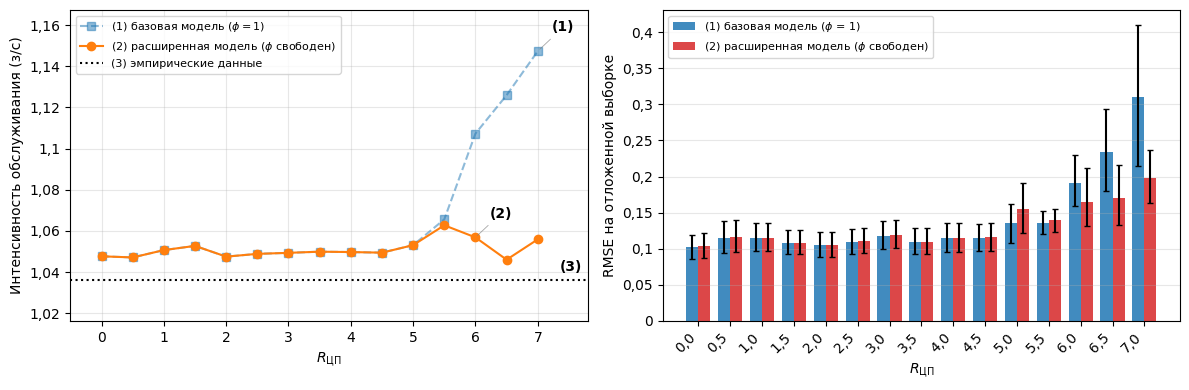

In [15]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter

comma_fmt = FuncFormatter(lambda x, _: f"{x:g}".replace(".", ","))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# ---------------------------------------------------------------
# ax1 — \hat mu_0
# ---------------------------------------------------------------
y_emp = 1 / succ["actual_service_time"].mean()

ax1.plot(calib  ["R_cpu"], calib  ["mu0_hat"], "s--", alpha=0.5,
         label=r"(1) базовая модель ($\phi = 1$)")
ax1.plot(calib2 ["R_cpu"], calib2 ["mu0_hat"], "o-",
         label=r"(2) расширенная модель ($\phi$ свободен)")
ax1.axhline(y_emp, color="k", ls=":",
            label="(3) эмпирические данные")

ax1.set_xlabel(r"$R_{\rm ЦП}$")
ax1.set_ylabel("Интенсивность обслуживания (з/с)")
ax1.xaxis.set_major_formatter(comma_fmt)
ax1.yaxis.set_major_formatter(comma_fmt)
ax1.grid(alpha=0.3)
ax1.margins(y=0.18)
ax1.legend(fontsize=8, loc="upper left")

# Extend x-limits to expose a small left margin for the (3) label
ax1.set_xlim(-0.5, 7.8)

# ---------------------------------------------------------------
# On-plot labels: (1) at R=7, (2) at R=6, (3) at x=-0.5
# ---------------------------------------------------------------
x_end      = calib2["R_cpu"].max()
y_end_base = calib.loc[calib["R_cpu"]  == x_end, "mu0_hat"].values[0]

x_mid      = 6.0
y_mid_ext  = calib2.loc[calib2["R_cpu"] == x_mid, "mu0_hat"].values[0]

_arr = dict(arrowstyle="-", lw=0.6, color="gray", alpha=0.7)

# (1) — baseline endpoint at R=7
ax1.annotate("(1)", xy=(x_end, y_end_base),
             xytext=(10, 12),                 # points, not data units
             textcoords="offset points",
             fontsize=10, fontweight="bold",
             ha="left", va="bottom",
             arrowprops=_arr, annotation_clip=False)

# (2) — extended curve at R=6
ax1.annotate("(2)", xy=(x_mid, y_mid_ext),
             xytext=(10, 12),
             textcoords="offset points",
             fontsize=10, fontweight="bold",
             ha="left", va="bottom",
             arrowprops=_arr, annotation_clip=False)

# (3) — empirical line, just to the right of the last tick
ax1.text(0.99, y_emp + 0.003, "(3)",
         transform=ax1.get_yaxis_transform(),
         fontsize=10, fontweight="bold",
         ha="right", va="bottom")

# ---------------------------------------------------------------
# ax2 — LONO RMSE: extended vs baseline
# ---------------------------------------------------------------
R = agg["R_cpu"].values
x = np.arange(len(R))
w = 0.38

yerr_ext  = np.vstack([agg["rmse_ext"]  - agg["ext_lo"],
                       agg["ext_hi"]   - agg["rmse_ext"]])
yerr_base = np.vstack([agg["rmse_base"] - agg["base_lo"],
                       agg["base_hi"]  - agg["rmse_base"]])

ax2.bar(x - w/2, agg["rmse_base"], w, yerr=yerr_base, capsize=2,
        color="C0", alpha=0.85, label=r"(1) базовая модель ($\phi$ = 1)")
ax2.bar(x + w/2, agg["rmse_ext"],  w, yerr=yerr_ext,  capsize=2,
        color="C3", alpha=0.85, label=r"(2) расширенная модель ($\phi$ свободен)")

ax2.set_xticks(x)
ax2.set_xticklabels([f"{r:.1f}".replace(".", ",") for r in R],
                    rotation=45, ha="right")
ax2.set_xlabel(r"$R_{\rm ЦП}$")
ax2.set_ylabel("RMSE на отложенной выборке")
ax2.yaxis.set_major_formatter(comma_fmt)
ax2.grid(alpha=0.3, axis="y")
ax2.legend(fontsize=8)

plt.tight_layout()
plt.savefig("Models_comparison.png", dpi=300)
plt.show()

In [16]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ---------------------------------------------------------------
# Inter-arrival times: pool across ALL files, diff per-experiment
# ---------------------------------------------------------------
# Every experiment (source_file, R_cpu, servers, m) has its own
# arrival_time_ms clock that restarts at 0, so np.diff must be
# applied *within* a group — sorting the pooled frame would
# interleave clocks and produce garbage intervals.
#
# Using `raw` (already cleaned, already tagged with source_file)
# guarantees the arrival sample covers the same data as `succ`.
def _inter_arrivals(g):
    t = g.sort_values("arrival_time_ms")["arrival_time_ms"].values / 1000.0
    return np.diff(t)

inter_arrivals = np.concatenate([
    _inter_arrivals(g)
    for _, g in raw.groupby(["source_file", "R_cpu", "servers", "m"])
])

# Millisecond timestamps can repeat -> zero-length intervals.
# These make Anderson–Darling return +inf (ln(0) = -inf), so drop them.
inter_arrivals = inter_arrivals[inter_arrivals > 0]

# ---------------------------------------------------------------
# Service times: successful requests only
# ---------------------------------------------------------------
service_times = succ["actual_service_time"].values
service_times = service_times[service_times > 0]

# Sanity check: arrivals should outnumber services by ~1/success_rate
print(f"Inter-arrival sample size: {len(inter_arrivals):,}")
print(f"Service-time sample size:  {len(service_times):,}")
print(f"Ratio (services / arrivals): {len(service_times)/len(inter_arrivals):.3f}")

Inter-arrival sample size: 1,124,262
Service-time sample size:  613,146
Ratio (services / arrivals): 0.545


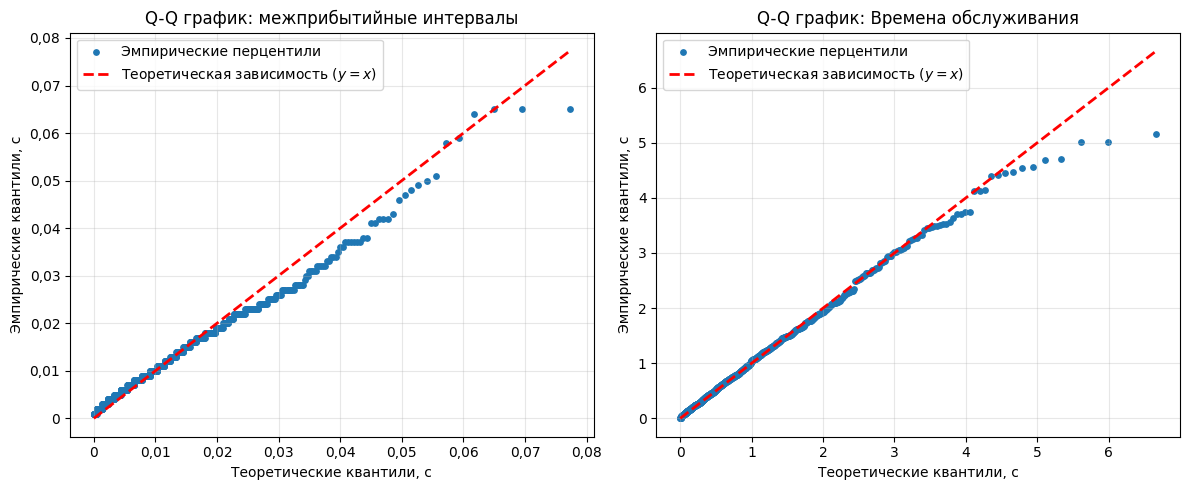

In [17]:
# Generate Q-Q Plots: inter-arrival times (left) and service times (right).
import scipy.stats as stats
from matplotlib.ticker import FuncFormatter

# Russian decimal separator: comma instead of dot
comma_fmt = FuncFormatter(lambda x, _: f"{x:g}".replace(".", ","))

fig, (ax_arr, ax_srv) = plt.subplots(1, 2, figsize=(12, 5))

def plot_qq(ax, data, title):
    scale = np.mean(data)
    percentiles = np.linspace(0.1, 99.9, 1000) / 100.0
    theoretical_quantiles = stats.expon.ppf(percentiles, scale=scale)
    empirical_quantiles = np.percentile(data, percentiles * 100)

    ax.scatter(theoretical_quantiles, empirical_quantiles, color='C0', s=15,
               label='Эмпирические перцентили')
    max_val = max(theoretical_quantiles.max(), empirical_quantiles.max())
    ax.plot([0, max_val], [0, max_val], 'r--', lw=2,
            label=r'Теоретическая зависимость ($y = x$)')
    ax.set_xlabel("Теоретические квантили, с")
    ax.set_ylabel("Эмпирические квантили, с")
    ax.set_title(title)
    ax.xaxis.set_major_formatter(comma_fmt)
    ax.yaxis.set_major_formatter(comma_fmt)
    ax.legend()
    ax.grid(alpha=0.3)

# Left panel: inter-arrival times.
# inter_arrivals is computed per (R_cpu, servers, m) cell and then pooled;
# because mean lambda varies by < 1% across cells, the pooled sample is
# approximately Exp(lambda-bar) and a single-scale Q-Q is meaningful.
plot_qq(ax_arr, inter_arrivals,
        "Q-Q график: межприбытийные интервалы")

# Right panel: service times.
plot_qq(ax_srv, service_times,
        "Q-Q график: Времена обслуживания")

plt.tight_layout()
plt.savefig("QQ_Plots_Validation.png", dpi=300)
plt.show()

In [18]:
def analyze_exponentiality(data, label):
    print(f"\n--- {label} ---")
    mean_val = np.mean(data)
    std_val  = np.std(data, ddof=1)
    cv       = std_val / mean_val
    def _fmt(v): return f"{v:.4f}".replace(".", ",")
    print(f"Объём выборки (N): {len(data)}")
    print(f"Среднее: {_fmt(mean_val)} с")
    print(f"СКО:     {_fmt(std_val)} с")
    print(f"Коэффициент вариации (CV): {_fmt(cv)}")

analyze_exponentiality(inter_arrivals, "Межприбытийные интервалы (пуассоновский поток)")
analyze_exponentiality(service_times,  "Времена обслуживания (экспоненциальное распределение)")


--- Межприбытийные интервалы (пуассоновский поток) ---
Объём выборки (N): 1124262
Среднее: 0,0112 с
СКО:     0,0096 с
Коэффициент вариации (CV): 0,8574

--- Времена обслуживания (экспоненциальное распределение) ---
Объём выборки (N): 613146
Среднее: 0,9650 с
СКО:     0,9098 с
Коэффициент вариации (CV): 0,9428


In [19]:
# =============================================================
# Q-analysis: which CPU quota q fits best?
# =============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy.optimize import differential_evolution
from joblib import Parallel, delayed

# Russian decimal comma formatter (same convention as the paper figures)
comma_fmt = FuncFormatter(lambda x, _: f"{x:g}".replace(".", ","))

# ----------------------------------------------------------------
# 1. Model with q as a free parameter
# ----------------------------------------------------------------
def model_metrics_v3(mu0, n, m, R_cpu, q, lam=LAM, A=A_GLOBAL, p=1.0):
    """Same as model_metrics_v2 but with q exposed as an argument."""
    if mu0 <= 0 or p <= 0 or q <= 0:
        raise ValueError("mu0, p, q must be positive")

    K = int(np.floor(n * p)) + m
    s_cpu = p * (A - R_cpu) / q
    s_cont = p * n
    s = int(np.floor(min(s_cpu, s_cont)))

    if s == 0:
        return dict(s=0, p=p, q=q, K=K, P_loss=1.0,
                    L=0.0, L_q=0.0, L_serv=0.0,
                    T=np.inf, T_q=np.inf, T_serv=np.inf,
                    lam_eff=0.0, pi=np.ones(1))

    a = lam / mu0
    rho = lam / (s * mu0)

    log_pi = np.zeros(K + 1)
    for k in range(1, s + 1):
        log_pi[k] = log_pi[k-1] + np.log(a) - np.log(k)
    for k in range(s + 1, K + 1):
        log_pi[k] = log_pi[k-1] + np.log(rho)
    log_pi -= log_pi.max()
    pi = np.exp(log_pi); pi /= pi.sum()

    P_loss = float(pi[K])
    L = float(np.dot(np.arange(K+1), pi))
    k_ax = np.arange(K+1)
    L_serv = float(np.dot(np.minimum(k_ax, s), pi))
    L_q = L - L_serv

    lam_eff = lam * (1.0 - P_loss)
    T      = L      / lam_eff if lam_eff > 0 else np.inf
    T_q    = L_q    / lam_eff if lam_eff > 0 else np.inf
    T_serv = L_serv / lam_eff if lam_eff > 0 else np.inf

    return dict(s=s, p=p, q=q, K=K, P_loss=P_loss,
                L=L, L_q=L_q, L_serv=L_serv,
                T=T, T_q=T_q, T_serv=T_serv,
                lam_eff=lam_eff, pi=pi)

# sanity: v3(q=8/240, p=1) == v2(p=1)
_r_old = model_metrics_v2(1.05, 20, 30, R_cpu=4.0, lam=90.0, p=1.0)
_r_new = model_metrics_v3(1.05, 20, 30, R_cpu=4.0,
                          q=8.0/240.0, lam=90.0, p=1.0)
assert abs(_r_old["P_loss"] - _r_new["P_loss"]) < 1e-12
assert abs(_r_old["T_serv"] - _r_new["T_serv"]) < 1e-12
print("PASS  v3(q=8/240, p=1) == v2(p=1)")

# ----------------------------------------------------------------
# 2. SSE with fixed q
# ----------------------------------------------------------------
def _sse_q(theta, sub, R, q, fix_p=None, w_T=1.0, w_L=0.0):
    mu0 = np.exp(theta[0])
    p   = float(fix_p) if fix_p is not None else np.exp(theta[1])
    lam_use = float(sub["lam_actual"].mean())
    tot = 0.0
    for n_i, m_i, pl, ts, ls in zip(sub["n"].astype(int),
                                    sub["m"].astype(int),
                                    sub["P_loss"].values,
                                    sub["T_serv"].values,
                                    sub["L_serv"].values):
        try:
            r = model_metrics_v3(mu0, n_i, m_i, R, q, lam=lam_use, p=p)
        except Exception:
            return 1e12
        if not np.isfinite(r["P_loss"]) or not np.isfinite(r["T_serv"]) or ts <= 0:
            return 1e12
        if not np.isfinite(r["L_serv"]) or ls <= 0:
            return 1e12
        tot += (r["P_loss"] - pl)**2
        tot += w_T * ((r["T_serv"] - ts) / ts)**2
        tot += w_L * ((r["L_serv"] - ls) / ls)**2
    return tot

# ----------------------------------------------------------------
# 3. Fit one R_cpu for a given q
# ----------------------------------------------------------------
def fit_R_with_q(grp, R, q, fit_p=True,
                 maxiter=150, popsize=10, tol=1e-6):
    if len(grp) < 10:
        return None
    if fit_p:
        bounds = [(np.log(0.05), np.log(50.0)),
                  (np.log(1.00), np.log(20.0))]
        func = lambda th: _sse_q(th, grp, R, q, fix_p=None)
    else:
        bounds = [(np.log(0.05), np.log(50.0))]
        func = lambda th: _sse_q(th, grp, R, q, fix_p=1.0)
    res = differential_evolution(func, bounds=bounds,
                                 seed=0, maxiter=maxiter,
                                 popsize=popsize, tol=tol,
                                 polish=False, workers=1)
    return dict(R_cpu=R, q=float(q),
                mu0=float(np.exp(res.x[0])),
                p=float(np.exp(res.x[1])) if fit_p else 1.0,
                SSE=float(res.fun), n_obs=len(grp))

# ----------------------------------------------------------------
# 4. Sweep q for a whole family of fits
# ----------------------------------------------------------------
def sweep_q(emp, q_grid, fit_p=True, n_jobs=-1):
    tasks = [(R, grp, float(q), fit_p)
             for q in q_grid
             for R, grp in emp.groupby("R_cpu")]
    print(f"{len(tasks)} подгонок  ({len(q_grid)} значений q × "
          f"{emp['R_cpu'].nunique()} групп $R_{{\\rm ЦП}}$)…")
    out = Parallel(n_jobs=n_jobs, verbose=5)(
        delayed(fit_R_with_q)(grp, R, q, fp) for R, grp, q, fp in tasks)
    return pd.DataFrame([r for r in out if r is not None])

def summarize_q(sweep_df):
    g = (sweep_df.groupby("q")
         .agg(total_SSE=("SSE", "sum"),
              total_obs=("n_obs", "sum"),
              n_fits=("SSE", "size"))
         .reset_index())
    g["RMSE"] = np.sqrt(g["total_SSE"] / g["total_obs"])
    return g

# Russian column names for the printed summaries
COLS_RU = {
    "q":         "$q$",
    "total_SSE": "SSE$_{\\rm сумм}$",
    "total_obs": "$N_{\\rm наб}$",
    "n_fits":    "$n_{\\rm подг}$",
    "RMSE":      "RMSE",
}

# ----------------------------------------------------------------
# 5. Run the sweep  (≈1–2 min on 10 cores)
# ----------------------------------------------------------------
q_grid = np.logspace(np.log10(0.008), np.log10(0.15), 20)

sweep_ext  = sweep_q(emp, q_grid, fit_p=True,  n_jobs=10)
sweep_base = sweep_q(emp, q_grid, fit_p=False, n_jobs=10)

sum_ext  = summarize_q(sweep_ext)
sum_base = summarize_q(sweep_base)

print("\n=== (2) Расширенная модель ($p$ свободен) — суммарная RMSE по $q$ ===")
print(sum_ext.rename(columns=COLS_RU).round(5).to_string(index=False))
print("\n=== (1) Базовая модель ($p = 1$) — суммарная RMSE по $q$ ===")
print(sum_base.rename(columns=COLS_RU).round(5).to_string(index=False))

PASS  v3(q=8/240, p=1) == v2(p=1)
300 подгонок  (20 значений q × 15 групп $R_{\rm ЦП}$)…


[Parallel(n_jobs=10)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=10)]: Done  52 tasks      | elapsed:  3.3min
[Parallel(n_jobs=10)]: Done 142 tasks      | elapsed:  8.4min
[Parallel(n_jobs=10)]: Done 268 tasks      | elapsed: 13.6min
[Parallel(n_jobs=10)]: Done 300 out of 300 | elapsed: 14.5min finished
[Parallel(n_jobs=10)]: Using backend LokyBackend with 10 concurrent workers.


300 подгонок  (20 значений q × 15 групп $R_{\rm ЦП}$)…


[Parallel(n_jobs=10)]: Done  52 tasks      | elapsed:   20.9s
[Parallel(n_jobs=10)]: Done 142 tasks      | elapsed:   53.1s
[Parallel(n_jobs=10)]: Done 268 tasks      | elapsed:  1.5min



=== (2) Расширенная модель ($p$ свободен) — суммарная RMSE по $q$ ===
    $q$  SSE$_{\rm сумм}$  $N_{\rm наб}$  $n_{\rm подг}$    RMSE
0.00800          35.74182           2256              15 0.12587
0.00933          35.74182           2256              15 0.12587
0.01089          35.73660           2256              15 0.12586
0.01271          35.61530           2256              15 0.12565
0.01483          35.63966           2256              15 0.12569
0.01730          35.70479           2256              15 0.12580
0.02019          35.81812           2256              15 0.12600
0.02356          35.87630           2256              15 0.12611
0.02748          35.99930           2256              15 0.12632
0.03207          36.10675           2256              15 0.12651
0.03742          36.27598           2256              15 0.12681
0.04366          36.52333           2256              15 0.12724
0.05094          37.43380           2256              15 0.12881
0.05944          38

[Parallel(n_jobs=10)]: Done 300 out of 300 | elapsed:  1.6min finished


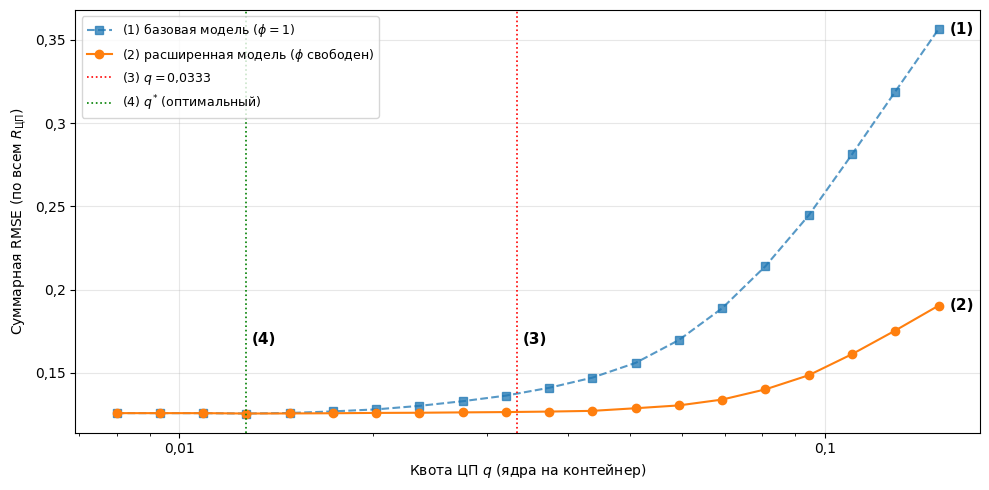

In [20]:

# ----------------------------------------------------------------
# 6. Plot the profiles  (legend = short text; numbers (1)–(4) on the plot)
# ----------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(sum_base["q"], sum_base["RMSE"], "s--", lw=1.5, alpha=0.75,
        label=r"(1) базовая модель ($\phi = 1$)")
ax.plot(sum_ext["q"],  sum_ext["RMSE"],  "o-",  lw=1.5,
        label=r"(2) расширенная модель ($\phi$ свободен)")

ax.axvline(Q_GLOBAL, color="r", ls=":", lw=1.2,
           label=r"(3) $q = 0{,}0333$")
i_ext = sum_ext["RMSE"].idxmin()
q_best_global = float(sum_ext.loc[i_ext, "q"])
ax.axvline(q_best_global, color="g", ls=":", lw=1.2,
           label=r"(4) $q^{*}$ (оптимальный)")

ax.set_xscale("log")
ax.set_xlabel(r"Квота ЦП $q$ (ядра на контейнер)")
ax.set_ylabel(r"Суммарная RMSE (по всем $R_{\rm ЦП}$)")
ax.xaxis.set_major_formatter(comma_fmt)
ax.yaxis.set_major_formatter(comma_fmt)
ax.grid(alpha=0.3)

# --- draw the axes limits once so the annotation anchors are known ---
fig.canvas.draw()
ymin, ymax = ax.get_ylim()
xmin, xmax = ax.get_xlim()

# (1) baseline — right endpoint of the curve
x1, y1 = float(sum_base["q"].iloc[-1]), float(sum_base["RMSE"].iloc[-1])
ax.annotate("(1)", xy=(x1, y1),
            xytext=(8, 0), textcoords="offset points",
            fontsize=11, fontweight="bold",
            va="center", ha="left", annotation_clip=False)

# (2) extended — right endpoint of the curve
x2, y2 = float(sum_ext["q"].iloc[-1]), float(sum_ext["RMSE"].iloc[-1])
ax.annotate("(2)", xy=(x2, y2),
            xytext=(8, 0), textcoords="offset points",
            fontsize=11, fontweight="bold",
            va="center", ha="left", annotation_clip=False)

# (3) q_ref — near the top of the vertical line
ax.annotate("(3)", xy=(Q_GLOBAL, ymax - 0.19),
            xytext=(4, -4), textcoords="offset points",
            fontsize=11, fontweight="bold",
            va="top", ha="left", annotation_clip=False)

# (4) q* — near the top of the vertical line
ax.annotate("(4)", xy=(q_best_global, ymax - 0.19),
            xytext=(4, -4), textcoords="offset points",
            fontsize=11, fontweight="bold", 
            va="top", ha="left", annotation_clip=False)

ax.legend(fontsize=9, loc="upper left")
plt.tight_layout()
plt.savefig("q_profile.png", dpi=300)
plt.show()

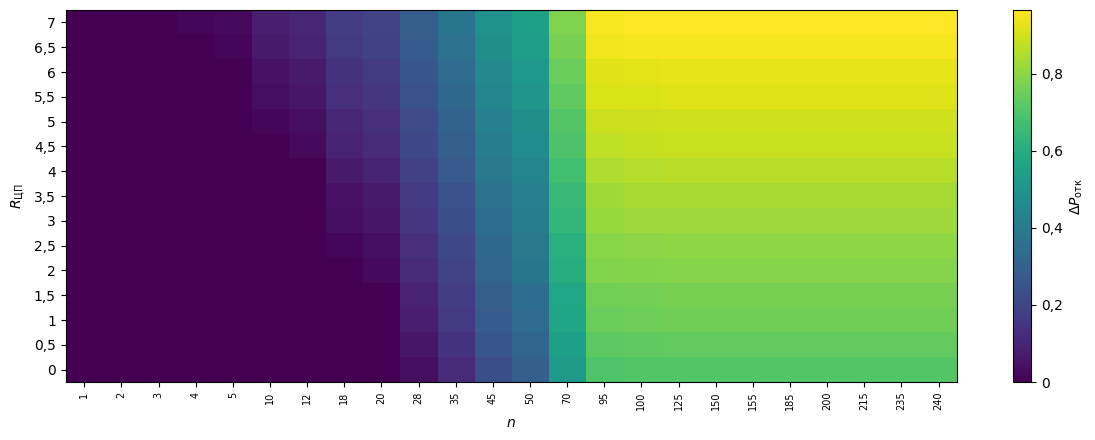

In [21]:
# ----------------------------------------------------------------
# 7. Where does q actually bite?  (sensitivity of P_loss to q)
# ----------------------------------------------------------------
def sensitivity_grid(q_vals, n_vals, R_vals, mu0=1.05, p=1.0):
    rows = []
    for R in R_vals:
        for n in n_vals:
            pls = []
            for q in q_vals:
                try:
                    r = model_metrics_v3(mu0, n, m=10, R_cpu=R, q=q, p=p)
                    pls.append(r["P_loss"])
                except Exception:
                    pls.append(np.nan)
            rows.append(dict(R_cpu=R, n=n,
                             P_loss_range=float(np.nanmax(pls) - np.nanmin(pls))))
    return pd.DataFrame(rows)

q_sens = np.logspace(np.log10(0.01), np.log10(0.32), 20)
sens = sensitivity_grid(q_sens,
                        sorted(emp["n"].unique()),
                        sorted(emp["R_cpu"].unique()))
piv = sens.pivot(index="R_cpu", columns="n", values="P_loss_range")

fig, ax = plt.subplots(figsize=(12, 4.5))
im = ax.imshow(piv.values, aspect="auto", origin="lower", cmap="viridis")
ax.set_xticks(range(len(piv.columns)))
ax.set_xticklabels(piv.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(piv.index)))
ax.set_yticklabels([f"{v:g}".replace(".", ",") for v in piv.index])
ax.set_xlabel(r"$n$")
ax.set_ylabel(r"$R_{\rm ЦП}$")
cbar = plt.colorbar(im, ax=ax)
cbar.set_label(r"$\Delta P_{\rm отк}$")
cbar.ax.yaxis.set_major_formatter(comma_fmt)
plt.tight_layout(); plt.savefig("q_sensitivity.png", dpi=300); plt.show()

In [22]:
# ----------------------------------------------------------------
# 8. Do individual R groups agree on a preferred q?
# ----------------------------------------------------------------
piv_sse = sweep_ext.pivot_table(index="R_cpu", columns="q", values="SSE")
best_q_per_R   = piv_sse.idxmin(axis=1)
best_sse_per_R = piv_sse.min(axis=1)
print("\n=== Наилучший $q$ при каждом $R_{\\rm ЦП}$ (расширенная модель) ===")
best_tbl = pd.DataFrame({
    "R_cpu":    best_q_per_R.index,
    "q_best":   best_q_per_R.values,
    "SSE_best": best_sse_per_R.values,
}).rename(columns={
    "R_cpu":    r"$R_{\rm ЦП}$",
    "q_best":   r"$q^*$",
    "SSE_best": r"SSE$^*$",
})
print(best_tbl.round(5).to_string(index=False))


=== Наилучший $q$ при каждом $R_{\rm ЦП}$ (расширенная модель) ===
 $R_{\rm ЦП}$   $q^*$  SSE$^*$
          0.0 0.09443  2.20177
          0.5 0.09443  2.80518
          1.0 0.09443  2.73634
          1.5 0.08093  2.20229
          2.0 0.08093  2.28408
          2.5 0.06936  2.31391
          3.0 0.06936  2.77075
          3.5 0.05944  2.39092
          4.0 0.05094  2.59510
          4.5 0.04366  2.52488
          5.0 0.04366  1.67479
          5.5 0.03207  1.81719
          6.0 0.02748  1.32165
          6.5 0.02019  1.00053
          7.0 0.01271  1.10030


In [23]:
for q_test in [1/15, 1/30, 1/60]:
    r1 = model_metrics_v3(1.05, 100, 10, 7.0, q_test, p=1.0)
    print(f"q = {q_test:.4f}   s = {r1['s']:3d}   K = {r1['K']:3d}   "
          f"P_loss = {r1['P_loss']:.4f}")
# q = 0.0667  s = 15  K = 110  P_loss = ...
# q = 0.0333  s = 30  K = 110  P_loss = ...
# q = 0.0167  s = 60  K = 110  P_loss = ...

q = 0.0667   s =  15   K = 110   P_loss = 0.8250
q = 0.0333   s =  30   K = 110   P_loss = 0.6500
q = 0.0167   s =  60   K = 110   P_loss = 0.3000
